# GraphCast Initial-Condition Sensitivity: 2025 Tennessee Valley Flood

How much does a rainfall forecast change when it starts one day later? In early April 2025 days of repeated heavy rain flooded the Ohio and Tennessee valleys, with the heaviest rain on 3 April. Here the same GraphCast Operational model (Google DeepMind, run through NVIDIA Earth2Studio) is started from two NOAA GFS analyses (the `GFS` data source loaded in section 3), 2025-04-01 00Z and 2025-04-02 00Z, and both runs extend to 2025-04-07 00Z. Their forecasts for April 2–5 are compared with each other (maps for 5 April and a daily series at Nashville) and with ERA5 daily precipitation over the Tennessee Valley box (33–40.5°N, 95–82°W). You will see how sensitive the rain forecast for this flood was to the initial condition, and how to score both runs against the same reference.

> **Measured on an NVIDIA L40:** 11 min runtime · 36.8 GiB peak GPU memory.

1. Setup
2. Configuration
3. Load GraphCast and the GFS data source
4. Run the two forecasts
5. Daily precipitation and map helpers
6. 5 April: the two forecasts side by side
7. Nashville time series
8. Verify against ERA5

## 1 · Setup

The environment variable must be set before PyTorch starts, so it comes first. `free_gpu(...)` releases GPU memory after each forecast, even if the cell fails.

In [1]:
# Environment: must be set before torch / earth2studio are imported.
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")  # JAX (GraphCast): allocate GPU memory on demand, not ~75% up front

import gc
import shutil
import warnings
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
import torch

import earth2studio.run as run
from earth2studio.data import GFS
from earth2studio.io import ZarrBackend
from earth2studio.models.px import GraphCastOperational

from era5_truth import compute_daily_total_precip

warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


def free_gpu(*names: str) -> None:
    """Delete the named notebook variables (models, tensors), collect garbage, and release cached CUDA memory."""
    scope = globals()
    for name in names:
        scope.pop(name, None)
    gc.collect()
    torch.cuda.empty_cache()


def map_colorbar(fig, ax, mappable, label=None, orientation="vertical", **kwargs):
    '''Colorbar attached to `ax` that is exactly as long as the drawn map (never longer).

    fig.colorbar(..., ax=ax, shrink=...) sizes the bar from the axes box before a map's fixed
    aspect ratio is applied, so on wide maps the bar comes out taller than the map.'''
    side, pad = ("right", 0.1) if orientation == "vertical" else ("bottom", 0.35)
    cax = make_axes_locatable(ax).append_axes(side, size="4%", pad=pad, axes_class=plt.Axes)
    return fig.colorbar(mappable, cax=cax, orientation=orientation, label=label, **kwargs)

Device: cuda


## 2 · Configuration

Every value a reader may want to change lives here: the two initial times, the days both runs cover, the day that is mapped, the region, the cities, and where outputs go.

In [2]:
# Event
EVENT_NAME = "2025 Tennessee Valley Flood"
EVENT_DATE = "2025-04-03"  # day with the heaviest rain

# Two forecasts one day apart; both reach Apr 7 00Z
FORECAST_INIT_A = "2025-04-01T00:00:00"
NSTEPS_A = 24  # 5 days (Apr 1 -> Apr 6 00:00) + buffer, covers through Apr 5

FORECAST_INIT_B = "2025-04-02T00:00:00"
NSTEPS_B = 20  # 4 days (Apr 2 -> Apr 6 00:00) + buffer, covers through Apr 5

# Comparison window: overlap of both forecast runs
COMPARE_DATES = ["2025-04-02", "2025-04-03", "2025-04-04", "2025-04-05"]
TARGET_DATE = "2025-04-05"  # day drawn as maps in section 6

# Tennessee Valley region [lon_min, lon_max, lat_min, lat_max]; also the ERA5 scoring box (era5_truth.TN_BOX)
EXTENT = [-95, -82, 33, 40.5]

# Point for the time series (longitude in 0-360)
POI_LAT = 36.16
POI_LON = 360 - 86.78
POI_LABEL = "Nashville, TN"

# Cities marked on the maps; Nashville is the point used for the time series in section 7
CITIES = [
    {"lat": 39.78, "lon": 360 - 89.65, "label": "Springfield, IL"},
    {"lat": 39.77, "lon": 360 - 86.16, "label": "Indianapolis, IN"},
    {"lat": 39.10, "lon": 360 - 84.51, "label": "Cincinnati, OH"},
    {"lat": 38.63, "lon": 360 - 90.20, "label": "St Louis, MO"},
    {"lat": 38.25, "lon": 360 - 85.76, "label": "Louisville, KY"},
    {"lat": 36.37, "lon": 360 - 94.21, "label": "Bentonville, AR"},
    {"lat": POI_LAT, "lon": POI_LON, "label": POI_LABEL},
    {"lat": 35.15, "lon": 360 - 90.05, "label": "Memphis, TN"},
]

# Outputs (paths relative to the notebook folder)
PROJECT = Path.cwd()  # JupyterLab and nbconvert both start in the notebook's folder
OUTPUT_DIR = "tn_flood_ic_compare_outputs"
ZARR_STORE_A = f"{OUTPUT_DIR}/graphcast_tn_ic0401.zarr"
ZARR_STORE_B = f"{OUTPUT_DIR}/graphcast_tn_ic0402.zarr"
RESULTS_DIR = PROJECT / "docs" / "results"  # small CSV metric tables that the README embeds
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 3 · Load GraphCast and the GFS data source

The model is loaded once and used for both runs, so the initial condition is the only thing that differs between them. GraphCast Operational needs no precipitation input, so an operational analysis such as GFS can start it.

In [3]:
package = GraphCastOperational.load_default_package()
model = GraphCastOperational.load_model(package)

# Initial states: the NOAA GFS analyses at the two initial times
data = GFS()

print("Model and data source loaded.")

Model and data source loaded.


## 4 · Run the two forecasts

Each run keeps only `tp06` (6-hour precipitation) in its own Zarr store. The model stays loaded after the first run and is released after the second.

### IC = April 1


In [4]:
try:
    io_a = ZarrBackend(ZARR_STORE_A, backend_kwargs={"overwrite": True})
    io_a = run.deterministic(
        [FORECAST_INIT_A],
        NSTEPS_A,
        model,
        data,
        io_a,
        output_coords={"variable": np.array(["tp06"])},
    )
except BaseException:
    shutil.rmtree(ZARR_STORE_A, ignore_errors=True)  # never leave a half-written forecast on disk
    raise
finally:
    free_gpu()  # release cached memory but keep the model for the second run

print(f"IC={FORECAST_INIT_A}")
print(io_a.root.tree())

2026-11-01 02:18:35.625 | INFO     | earth2studio.run:deterministic:85 - Running simple workflow!
2026-11-01 02:18:35.626 | INFO     | earth2studio.run:deterministic:92 - Inference device: cuda


2026-11-01 02:18:36.861 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 263890850-821344


2026-11-01 02:18:37.390 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 224830970-1128485
2026-11-01 02:18:37.443 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 284890981-819827


2026-11-01 02:18:37.573 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 246887959-1158743
2026-11-01 02:18:37.753 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 306748053-874917
2026-11-01 02:18:37.772 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 267990822-1168942


2026-11-01 02:18:37.876 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 341333577-915254
2026-11-01 02:18:37.924 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 288915077-1184649


2026-11-01 02:18:37.978 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 365577183-955670
2026-11-01 02:18:38.139 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 310859016-1205719
2026-11-01 02:18:38.172 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 410733421-1013963


... (51 outputs left out)

E1101 02:20:57.059804    3078 slow_operation_alarm.cc:74] 
********************************
[Compiling module input_reduce_fusion for GPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************


E1101 02:22:46.347872    3058 slow_operation_alarm.cc:141] The operation took 3m49.288194145s

********************************
[Compiling module input_reduce_fusion for GPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************


2026-11-01 02:24:07.099 | SUCCESS  | earth2studio.run:deterministic:189 - 
Inference complete


IC=2025-04-01T00:00:00
/
├── lat (721,) float64
├── lead_time (25,) timedelta64[h]
├── lon (1440,) float64
├── time (1,) datetime64[ns]
└── tp06 (1, 25, 721, 1440) float32



### IC = April 2


In [5]:
try:
    io_b = ZarrBackend(ZARR_STORE_B, backend_kwargs={"overwrite": True})
    io_b = run.deterministic(
        [FORECAST_INIT_B],
        NSTEPS_B,
        model,
        data,
        io_b,
        output_coords={"variable": np.array(["tp06"])},
    )
except BaseException:
    shutil.rmtree(ZARR_STORE_B, ignore_errors=True)  # never leave a half-written forecast on disk
    raise
finally:
    free_gpu("model", "package")

print(f"IC={FORECAST_INIT_B}")
print(io_b.root.tree())

2026-11-01 02:24:07.578 | INFO     | earth2studio.run:deterministic:85 - Running simple workflow!
2026-11-01 02:24:07.578 | INFO     | earth2studio.run:deterministic:92 - Inference device: cuda


2026-11-01 02:24:07.720 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 160024898-854230


2026-11-01 02:24:07.721 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 367944424-1217679
2026-11-01 02:24:07.804 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 181808216-929605


2026-11-01 02:24:07.933 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 0-889173
2026-11-01 02:24:08.104 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 401427511-996985
2026-11-01 02:24:08.146 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 192648063-944437
2026-11-01 02:24:08.193 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 218189106-732622


2026-11-01 02:24:08.282 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 156686042-1111015
2026-11-01 02:24:08.331 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 203344490-592465
2026-11-01 02:24:08.372 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 178134974-1239768


2026-11-01 02:24:08.526 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 213766963-598396
2026-11-01 02:24:08.640 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 189334156-1157806
2026-11-01 02:24:08.692 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 224453887-611805
2026-11-01 02:24:08.693 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250401/18/atmos/gfs.t18z.pgrb2.0p25.f000 200046729-1174922


... (40 outputs left out)

2026-11-01 02:24:19.409 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250402/00/atmos/gfs.t00z.pgrb2.0p25.f000 158217606-859225
2026-11-01 02:24:19.412 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250402/00/atmos/gfs.t00z.pgrb2.0p25.f000 341531292-1222958
2026-11-01 02:24:19.442 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250402/00/atmos/gfs.t00z.pgrb2.0p25.f000 365559824-1204727


2026-11-01 02:24:20.159 | SUCCESS  | earth2studio.run:deterministic:154 - Fetched data from GFS
2026-11-01 02:24:20.160 | INFO     | earth2studio.run:deterministic:162 - Inference starting!


2026-11-01 02:24:45.335 | SUCCESS  | earth2studio.run:deterministic:189 - 
Inference complete


IC=2025-04-02T00:00:00
/
├── lat (721,) float64
├── lead_time (21,) timedelta64[h]
├── lon (1440,) float64
├── time (1,) datetime64[ns]
└── tp06 (1, 21, 721, 1440) float32



## 5 · Daily precipitation and map helpers

Each `tp06` value is the rain (in metres) that fell in the 6 hours ending at that step's valid time; step 0 is the initial state and is all zeros. A UTC day D is the sum of the four steps valid at D 06Z, 12Z, 18Z and D+1 00Z, which is the window (D 00Z, D+1 00Z], for both runs alike. The ERA5 daily totals in section 8 use the same window. Both `compute_daily_total_precip` and the ERA5 daily totals live in `era5_truth.py`, whose unit tests check that the two use the same day.

In [6]:
PRECIP_LEVELS = [1, 5, 10, 20, 30, 50, 75, 100, 150]
PRECIP_CMAP = plt.cm.rainbow_r  # red = light rain, blue-purple = heavy rain
PRECIP_NORM = mcolors.BoundaryNorm(PRECIP_LEVELS, PRECIP_CMAP.N, extend="max")


def _draw_precip_axes(ax, precip, label, lon, lat, extent, poi=None):
    """Draw one daily-precip field onto a cartopy axes; return the contourf mappable."""
    # extend="max" colours totals above the top level instead of leaving them blank
    im = ax.contourf(
        lon, lat, precip,
        levels=PRECIP_LEVELS, cmap=PRECIP_CMAP, norm=PRECIP_NORM,
        transform=ccrs.PlateCarree(), extend="max",
    )
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor="gray")
    ax.add_feature(cfeature.BORDERS, linewidth=0.8)
    ax.coastlines(linewidth=0.8)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 8}
    gl.ylabel_style = {"size": 8}
    ax.set_extent(extent)

    for city in poi or []:
        ax.plot(
            city["lon"] - 360, city["lat"],
            marker="*", color="lime", markersize=7,
            markeredgecolor="black", markeredgewidth=0.5,
            transform=ccrs.PlateCarree(), zorder=5,
        )
        ax.text(
            city["lon"] - 360 + 0.15, city["lat"] + 0.15, city["label"],
            fontsize=7, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.8),
            transform=ccrs.PlateCarree(), zorder=5,
        )
    ax.set_title(label, fontsize=11)
    return im


def plot_single_panel(precip, label, lon, lat, extent, poi=None, save_path=None):
    """One daily-precip map in the tall house layout."""
    plt.close("all")

    fig, ax = plt.subplots(
        subplot_kw={"projection": ccrs.PlateCarree()},
        figsize=(6, 8),
    )
    im = _draw_precip_axes(ax, precip, label, lon, lat, extent, poi=poi)
    cbar = map_colorbar(fig, ax, im, label="Total Precipitation (mm)", orientation="horizontal")
    cbar.ax.tick_params(labelsize=8)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


def plot_panels(precips, labels, lon, lat, extent, poi=None, save_path=None):
    """N daily-precip maps stacked top to bottom (tall layout), same colour scale, each with its own colour bar."""
    plt.close("all")

    nrows = len(precips)
    fig, axes = plt.subplots(
        nrows, 1,
        subplot_kw={"projection": ccrs.PlateCarree()},
        figsize=(6, 4.9 * nrows),  # 4.9 in per row: room for each bar's label above the next title
        squeeze=False,
    )

    for ax, precip, label in zip(axes[:, 0], precips, labels):
        im = _draw_precip_axes(ax, precip, label, lon, lat, extent, poi=poi)
        cbar = map_colorbar(fig, ax, im, label="Total Precipitation (mm)", orientation="horizontal")
        cbar.ax.tick_params(labelsize=8)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()

## 6 · 5 April: the two forecasts side by side

Mapping the same day from both runs shows directly how the one-day-later start moved or changed the rain. The printed numbers are each run's largest daily total anywhere on the globe.

In [7]:
precip_a = compute_daily_total_precip(io_a, TARGET_DATE, FORECAST_INIT_A)
precip_b = compute_daily_total_precip(io_b, TARGET_DATE, FORECAST_INIT_B)

print("GraphCast IC=Apr1 max:", precip_a.max())
print("GraphCast IC=Apr2 max:", precip_b.max())

GraphCast IC=Apr1 max: 124.06647
GraphCast IC=Apr2 max: 117.860435


### April 5 map — IC=Apr1 vs IC=Apr2


Saved: tn_flood_ic_compare_outputs/graphcast_ic_compare_apr5.png


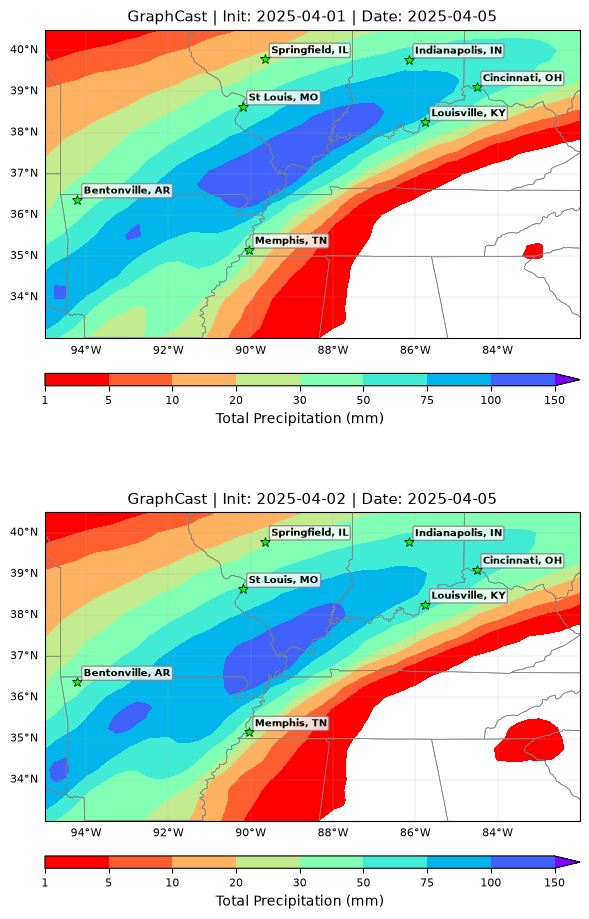

In [8]:
plot_panels(
    [precip_a, precip_b],
    [
        f"GraphCast | Init: {FORECAST_INIT_A[:10]} | Date: {TARGET_DATE}",
        f"GraphCast | Init: {FORECAST_INIT_B[:10]} | Date: {TARGET_DATE}",
    ],
    io_a["lon"][:], io_a["lat"][:], EXTENT, poi=CITIES,
    save_path=f"{OUTPUT_DIR}/graphcast_ic_compare_apr5.png",
)

**How to read this.** Top: the forecast started on 1 April (a 5-day forecast for 5 April); bottom: the forecast started on 2 April (a 4-day forecast for the same day). Both use the same red (light, from 1 mm) to blue-purple (heavy, 150 mm and more) scale; white means less than 1 mm. Compare where the heavy band lies relative to the marked cities: a large shift between the panels means the rain forecast was sensitive to the initial condition. The next two cells draw each map on its own.

Saved: tn_flood_ic_compare_outputs/graphcast_ic0401_apr5.png


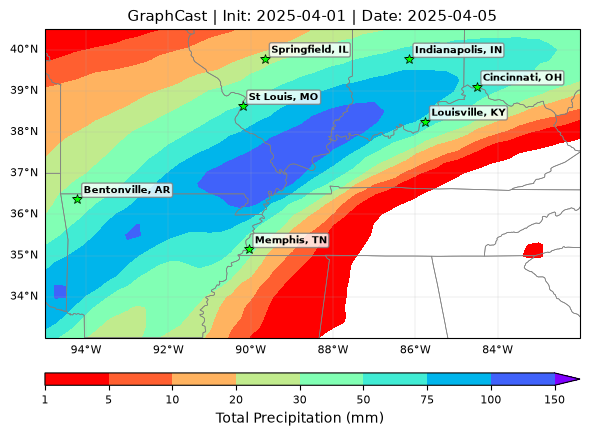

In [9]:
plot_single_panel(
    precip_a,
    f"GraphCast | Init: {FORECAST_INIT_A[:10]} | Date: {TARGET_DATE}",
    io_a["lon"][:], io_a["lat"][:], EXTENT, poi=CITIES,
    save_path=f"{OUTPUT_DIR}/graphcast_ic0401_apr5.png",
)

Saved: tn_flood_ic_compare_outputs/graphcast_ic0402_apr5.png


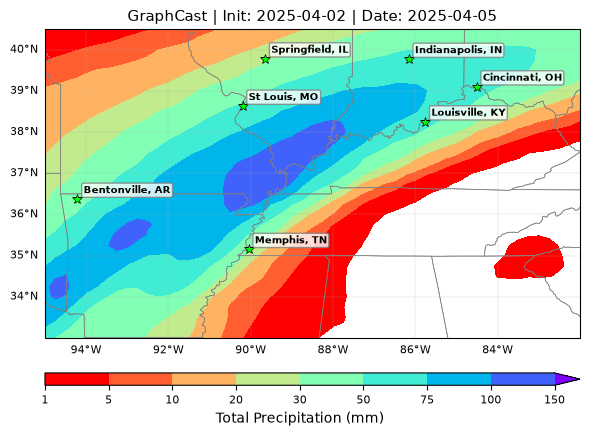

In [10]:
plot_single_panel(
    precip_b,
    f"GraphCast | Init: {FORECAST_INIT_B[:10]} | Date: {TARGET_DATE}",
    io_b["lon"][:], io_b["lat"][:], EXTENT, poi=CITIES,
    save_path=f"{OUTPUT_DIR}/graphcast_ic0402_apr5.png",
)

## 7 · Nashville time series

A single point shows the day-by-day difference between the two runs at a city that flooded. The values come from the nearest 0.25° grid cell.

In [11]:
lat_idx = np.argmin(np.abs(io_a["lat"][:] - POI_LAT))
lon_idx = np.argmin(np.abs(io_a["lon"][:] - POI_LON))

vals_a = [compute_daily_total_precip(io_a, date, FORECAST_INIT_A)[lat_idx, lon_idx] for date in COMPARE_DATES]
vals_b = [compute_daily_total_precip(io_b, date, FORECAST_INIT_B)[lat_idx, lon_idx] for date in COMPARE_DATES]

print(f'{"Date":12s} {"IC=Apr1 (mm)":>14s} {"IC=Apr2 (mm)":>14s}')
for date, va, vb in zip(COMPARE_DATES, vals_a, vals_b):
    print(f"{date:12s} {va:14.2f} {vb:14.2f}")

Date           IC=Apr1 (mm)   IC=Apr2 (mm)
2025-04-02             1.61           2.44
2025-04-03            59.18          43.40
2025-04-04            27.37          33.00
2025-04-05             1.66           2.02


Saved: tn_flood_ic_compare_outputs/nashville_precip_ic_compare.png


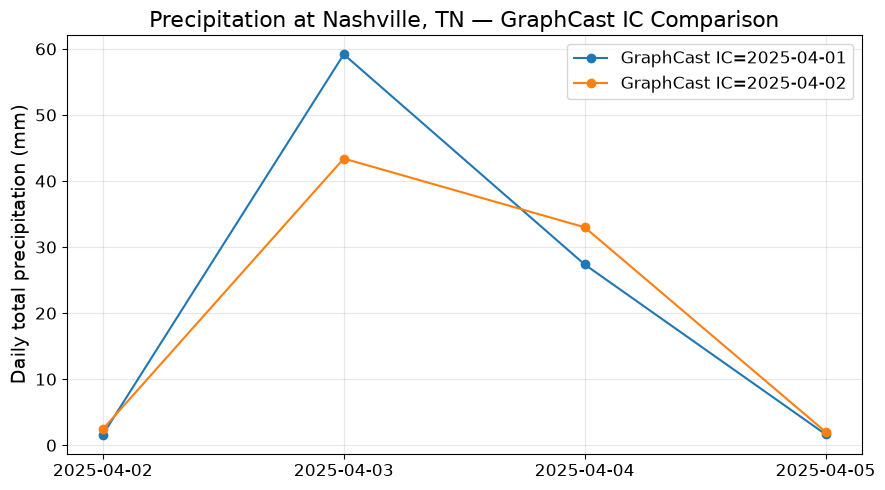

In [12]:
plt.close("all")
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(COMPARE_DATES, vals_a, marker="o", label=f"GraphCast IC={FORECAST_INIT_A[:10]}")
ax.plot(COMPARE_DATES, vals_b, marker="o", label=f"GraphCast IC={FORECAST_INIT_B[:10]}")
ax.set_ylabel("Daily total precipitation (mm)", fontsize=14)
ax.set_title(f"Precipitation at {POI_LABEL} — GraphCast IC Comparison", fontsize=16)
ax.tick_params(axis="both", labelsize=12)
ax.legend(fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()

save_path = f"{OUTPUT_DIR}/nashville_precip_ic_compare.png"
fig.savefig(save_path, dpi=150, bbox_inches="tight")
print(f"Saved: {save_path}")
plt.show()

**How to read this.** Each line is one run's daily total (mm) at the grid cell nearest Nashville (the star labelled Nashville, TN on the maps above), for the days both runs cover. Where the lines diverge, the initial condition changed the point forecast; a single grid cell is noisy, so read this together with the maps above.

## 8 · Verify against ERA5

Which start date gave the better rainfall forecast? Each run's daily totals for April 2–5 are compared with ERA5 daily totals for the same UTC windows over the Tennessee Valley box (33–40.5°N, 95–82°W, `era5_truth.TN_BOX`) on the model's 0.25° grid. Hourly ERA5 precipitation comes from the Copernicus Climate Data Store (it needs `~/.cdsapirc` credentials) and is cached in `OUTPUT_DIR`.

> **Truth caveat:** ERA5 precipitation is itself model-derived (it is a reanalysis product), so these scores measure agreement with ERA5, not with rain gauges or radar.

**How to read the tables.** The first table has one row per run and day; the second averages April 2–5 for each run. Bias = forecast − ERA5 in mm/day (positive means too wet), averaged over the box with area weights; RMSE and MAE are the typical size of the point-by-point error in mm/day; Pattern corr = spatial correlation of the daily rainfall pattern (1 means the rain is in the right places, whatever the amounts). On a given date the April 2 run has a one-day shorter lead time, so it is expected to score better; a large gap points to sensitivity to the initial condition.

In [13]:
from era5_truth import TN_ERA5_AREA, fetch_era5_daily_precip, forecast_vs_era5
from metrics import skill_row

era5_daily = fetch_era5_daily_precip(COMPARE_DATES, TN_ERA5_AREA, f"{OUTPUT_DIR}/era5_tp_tn.nc")
lat, lon = io_a["lat"][:], io_a["lon"][:]
runs = {"IC Apr 1": (io_a, FORECAST_INIT_A), "IC Apr 2": (io_b, FORECAST_INIT_B)}

rows = []
for date in COMPARE_DATES:
    for label, (run_store, init) in runs.items():
        fc, ref, lats = forecast_vs_era5(
            compute_daily_total_precip(run_store, date, init),
            era5_daily.sel(day=np.datetime64(date)), lat, lon,
        )
        rows.append({"Initial condition": label, "Date": date, **skill_row(fc, ref, lats)})

daily_skill = pd.DataFrame(rows)
nan_days = daily_skill.loc[daily_skill.isna().any(axis=1), "Date"].unique()
if len(nan_days):  # an incomplete ERA5 or forecast day must not be averaged away silently
    raise ValueError(f"NaN skill score on {', '.join(nan_days)}: incomplete ERA5 or forecast data for that day")
metrics_df = (
    daily_skill.groupby("Initial condition")[["Bias", "RMSE", "MAE", "Pattern corr"]]
    .mean().round(3).reset_index()
)
daily_skill.to_csv(RESULTS_DIR / "graphcast_tennessee_valley_flood_ic_compare_daily.csv", index=False)
metrics_df.to_csv(RESULTS_DIR / "graphcast_tennessee_valley_flood_ic_compare_metrics.csv", index=False)
print("Daily skill vs ERA5 (mm/day; Bias = forecast - ERA5)\n")
print(daily_skill.to_string(index=False))
print("\nMean over Apr 2-5\n")
print(metrics_df.to_string(index=False))

2026-11-01 02:25:03,705 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


2026-11-01 02:25:04,474 INFO Request ID is 84adbd0b-9549-4785-ad35-2336db14c01b


INFO:ecmwf.datastores.legacy_client:Request ID is 84adbd0b-9549-4785-ad35-2336db14c01b


2026-11-01 02:25:04,656 INFO status has been updated to successful


INFO:ecmwf.datastores.legacy_client:status has been updated to successful


Daily skill vs ERA5 (mm/day; Bias = forecast - ERA5)

Initial condition       Date   Bias   RMSE    MAE  Pattern corr
         IC Apr 1 2025-04-02 -0.442  7.798  4.896         0.787
         IC Apr 2 2025-04-02  0.505  7.676  5.044         0.781
         IC Apr 1 2025-04-03 -0.390 14.638  8.819         0.833
         IC Apr 2 2025-04-03  1.032 11.513  6.514         0.904
         IC Apr 1 2025-04-04  3.811 12.996  9.043         0.753
         IC Apr 2 2025-04-04  2.171 14.415  9.497         0.654
         IC Apr 1 2025-04-05  2.276 20.814 13.249         0.810
         IC Apr 2 2025-04-05  2.412 18.887 12.497         0.841

Mean over Apr 2-5

Initial condition  Bias   RMSE   MAE  Pattern corr
         IC Apr 1 1.314 14.062 9.002         0.796
         IC Apr 2 1.530 13.123 8.388         0.795


## Summary

- **5 April maps (section 6):** did starting one day later move or reshape the heavy-rain band over the Tennessee and Ohio valleys?
- **Nashville time series (section 7):** at one flooded city, how different are the two runs from day to day?
- **ERA5 skill tables (section 8):** for April 2–5 over the Tennessee Valley box, which run is closer to ERA5 in amount (Bias, RMSE, MAE) and in pattern (Pattern corr)? Keep in mind that the April 2 run has the shorter lead time and that ERA5 precipitation is itself model-derived.

The scores are saved to `docs/results/graphcast_tennessee_valley_flood_ic_compare_metrics.csv` (mean over April 2–5) and `docs/results/graphcast_tennessee_valley_flood_ic_compare_daily.csv` (per day); the figures are PNGs in `tn_flood_ic_compare_outputs/`.